# channel_ftdma — Filtered_TDMA 검증: 256³ DNS Re_τ 180, 2x2x2 (2026-10-28)

PaScaL(정확해) 과 Filtered(절단 근사) 를 **운동량 ADI 의 TDMA 만** 바꿔 같은 덱으로 돌린 두 런의 통계·J·시간 비교.
압력 Poisson 의 z TDMA 는 두 빌드 모두 PaScaL (`src/linear_solver/tdma/tdma.hpp`).

- 덱 `input_dns256_<backend>_2x2x2.ini` — 박스 4π × 2π × 2, 256³, Re_b 2857 (Re_τ ≈ 180), tanh z (γ 3), DNS (LES 없음), CFR.
  분할 2x2x2 = GH200 8 장 (랭크당 1 장) → **x·y·z 세 축 모두 분산** — Filtered 가 세 축 모두에서 절단한다.
- 20 만 스텝, 통계 2 만 스텝부터 1 만 스텝마다 누적 파일 → **구간(연속한 두 파일 사이) 평균**으로 풀어 구간 간 흩어짐으로 표준오차 σ.
- 판정: Filtered − PaScaL 을 결합 표준오차로 나눈 **z 값**. |z| ≲ 2 이면 통계 오차 안. 프로파일의 max|z| 는 128 개 z⁺ 점의 최대라
  같은 분포여도 3 안팎이 나온다 → **rms|z| ≈ 1** 이 '같음'의 기대값. 참조는 MKM 1999 Re_τ 180 DNS.
- J: `stats_<tag>/truncation_J.dat` (모니터 스텝마다, 랭크·성분·축별). 랭크당 128 행이라 J 범위 0..126.
- 시간: **통계 런 자체**에서 잰다 — 모니터 sec/step(100 스텝 평균)과 잡 시작·끝 벽시계. 두 런은 서로 다른 노드쌍에서 동시에 돌았다
  (노드 차이가 섞인다; 로그 `log/ftdma_<backend>_<job>.out` 첫 줄에 노드).
- 실행 중인 런은 지금까지 끝난 구간만 쓴다(표에 `진행 중`). 다시 실행하면 채워진다.

In [1]:
import glob, os, re
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

APP = os.path.abspath(os.path.join(os.getcwd(), ".."))
REF = os.path.abspath(os.path.join(APP, "..", "channel", "plot"))
LZ, DELTA = 2.0, 1.0
TAGS = {"pascal": "dns256_pascal_2x2x2", "filtered": "dns256_filtered_2x2x2"}
COLOR = {"pascal": "#2a78d6", "filtered": "#e8590c"}
LS = {"pascal": "-", "filtered": "--"}
AXIS_COLOR = {"x": "#2a78d6", "y": "#1baf7a", "z": "#e8590c"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.8, "legend.frameon": False, "legend.fontsize": 8,
})

In [2]:
def read_cumulative(path):
    with open(path) as f:
        h = [f.readline() for _ in range(2)]
    samples = int(re.search(r"samples=(\d+)", h[0]).group(1))
    nu = float(re.search(r"nu=([-0-9.eE+]+)", h[1]).group(1))
    return samples, nu, np.loadtxt(path, comments="#")

def wall_factor(path, nu, d):
    """코드의 u_τ = √(½ν(|U₁|/dmz_b + |U_N|/dmz_t)) 에서 dmz = c × (벽~첫 셀 중심). c 를 헤더 u_tau 로 역산
    (value ghost → c = 2: 중심~ghost 중심 거리, mirror → c = 1). 구간 u_τ 를 코드와 같은 정의로 만든다."""
    u_tau_header = float(re.search(r"u_tau=([-0-9.eE+]+)", open(path).readlines()[1]).group(1))
    z, U = d[:, 0], d[:, 2]
    return 0.5 * nu * (abs(U[0]) / z[0] + abs(U[-1]) / (LZ - z[-1])) / u_tau_header**2

def windows(tag):
    """누적 통계 파일들을 차분해 구간 평균으로 (z 반쪽 접기 전)."""
    out, prev, c = [], None, None
    for p in sorted(glob.glob(f"{APP}/stats_{tag}/channel_stats_*.dat")):
        n, nu, d = read_cumulative(p)
        if c is None: c = wall_factor(p, nu, d)
        z, U, ur, vr, wr, uw = d[:, 0], d[:, 2], d[:, 4], d[:, 5], d[:, 6], d[:, 7]
        s = dict(u=U * n, uu=(ur**2 + U**2) * n, vv=vr**2 * n, ww=wr**2 * n, uw=uw * n)
        if prev is not None and n > prev[0]:
            m = n - prev[0]
            b = {k: (s[k] - prev[1][k]) / m for k in s}
            u_tau = np.sqrt(0.5 * nu * (abs(b["u"][0]) / (c * z[0]) + abs(b["u"][-1]) / (c * (LZ - z[-1]))))
            out.append(dict(z=z, nu=nu, u_tau=u_tau, wall_factor=c, U=b["u"], urms=np.sqrt(np.maximum(b["uu"] - b["u"]**2, 0)),
                            vrms=np.sqrt(b["vv"]), wrms=np.sqrt(b["ww"]), uw=b["uw"], samples=m))
        prev = (n, s)
    return out

def fold(a, sign=1):
    nz = len(a); k = np.arange(nz // 2)
    return 0.5 * (a[k] + sign * a[nz - 1 - k])

def summarize(ws):
    w = np.array([x["samples"] for x in ws], float)
    def ms(vals):
        v = np.array(vals); return np.average(v, axis=0, weights=w), np.std(v, axis=0, ddof=1) / np.sqrt(len(v))
    z = ws[0]["z"]; nz = len(z)
    r = dict(nb=len(ws), samples=int(w.sum()))
    r["zp"] = fold(np.minimum(z, LZ - z)) * np.mean([x["u_tau"] for x in ws]) / ws[0]["nu"]
    r["re_tau"] = ms([x["u_tau"] * DELTA / x["nu"] for x in ws])
    r["Up"] = ms([fold(x["U"]) / x["u_tau"] for x in ws])
    for k in ("urms", "vrms", "wrms"): r[k] = ms([fold(x[k]) / x["u_tau"] for x in ws])
    r["uw"] = ms([-fold(x["uw"], -1) / x["u_tau"]**2 for x in ws])
    r["Uc"] = ms([0.5 * (x["U"][nz // 2 - 1] + x["U"][nz // 2]) / x["u_tau"] for x in ws])
    r["upeak"] = ms([np.max(fold(x["urms"])) / x["u_tau"] for x in ws])
    r["Ub_over_utau"] = ms([1.0 / x["u_tau"] for x in ws])   # CFR: U_b = 1 → U_b⁺ = 1/u_τ
    return r

def read_monitor(tag):
    path = f"{APP}/log/{tag}.log"
    if not os.path.exists(path): return None, False
    rows, done = [], False
    for line in open(path):
        if line.startswith("# FINAL"): done = True
        parts = line.split()
        if len(parts) == 9 and re.match(r"^\s+\d+\s", line): rows.append([float(x) for x in parts])
    d = np.array(rows)
    return dict(step=d[:, 0], time=d[:, 1], dt=d[:, 2], div=d[:, 4], re_tau=d[:, 6], sec=d[:, 8]), done

runs = {}
for be, tag in TAGS.items():
    ws = windows(tag); mon, done = read_monitor(tag)
    if len(ws) < 3:
        print(f"{tag}: 구간 {len(ws)} 개 — 통계 비교에서 뺌"); runs[be] = dict(monitor=mon, done=done, nb=len(ws)); continue
    runs[be] = dict(monitor=mon, done=done, **summarize(ws))
mean180 = np.loadtxt(f"{REF}/ref_mean_180.txt", comments="%"); fluc180 = np.loadtxt(f"{REF}/ref_fluc_180.txt", comments="%")
mkm = dict(zp=mean180[:, 1], Up=mean180[:, 2], urms=np.sqrt(fluc180[:, 2]), wrms=np.sqrt(fluc180[:, 3]),   # MKM v = 벽수직 → 우리 w
           vrms=np.sqrt(fluc180[:, 4]), uw=-fluc180[:, 5])                                                  # MKM w = 스팬 → 우리 v
RE_MKM = mean180[-1, 1]
stat_ok = all("re_tau" in runs[b] for b in TAGS)
print("벽 거리 계수 c (code dmz = c·z₁):", {b: round(windows(t)[0]["wall_factor"], 4) for b, t in TAGS.items() if windows(t)})
print("런:", ", ".join(f"{b} ({'완료' if r['done'] else '진행 중'}, 구간 {r['nb']})" for b, r in runs.items()), f"| MKM Re_tau {RE_MKM:.2f}")

벽 거리 계수 c (code dmz = c·z₁): {'pascal': np.float64(2.0), 'filtered': np.float64(2.0)}
런: pascal (완료, 구간 17), filtered (완료, 구간 17) | MKM Re_tau 180.56


## 1. 요약 표 — 창 평균 ± 표준오차, Filtered − PaScaL 의 z 값, MKM 대비

In [3]:
PROFILE_KEYS = [("Up", "U⁺"), ("urms", "u_rms⁺"), ("vrms", "v_rms⁺ (spanwise)"), ("wrms", "w_rms⁺ (wall-normal)"), ("uw", "−u′w′⁺")]
def zval(a, b, k): return (a[k][0] - b[k][0]) / np.sqrt(a[k][1]**2 + b[k][1]**2)
def mkm_at(key, zp): return np.interp(zp, mkm["zp"], mkm[key])
if stat_ok:
    P, F = runs["pascal"], runs["filtered"]
    print(f"{'':<10} {'구간':>4} {'Re_tau':>18} {'U_c+':>16} {'u_rms+ 정점':>16} {'U_b+':>16}")
    for be in TAGS:
        r = runs[be]; f = lambda q: f"{r[q][0]:8.3f}±{r[q][1]:6.3f}"
        print(f"{be:<10} {r['nb']:4d} {f('re_tau'):>18} {f('Uc'):>16} {f('upeak'):>16} {f('Ub_over_utau'):>16}")
    print(f"{'MKM 180':<10} {'':>4} {RE_MKM:18.2f} {np.max(mkm['Up']):16.3f} {np.max(mkm['urms']):16.3f}")
    print("\nFiltered − PaScaL:")
    for q, name in (("re_tau", "Re_tau"), ("Uc", "U_c+"), ("upeak", "u_rms+ 정점"), ("Ub_over_utau", "U_b+")):
        d = F[q][0] - P[q][0]
        print(f"  {name:<12} Δ = {d:+.4f} ({100 * d / P[q][0]:+.3f} %)   z = {zval(F, P, q):+.2f}")
    for k, name in PROFILE_KEYS:
        zz = np.abs(zval(F, P, k)); rel = np.max(np.abs(F[k][0] - P[k][0])) / np.max(np.abs(P[k][0]))
        print(f"  {name:<12} max|z| = {zz.max():.2f}   rms|z| = {np.sqrt(np.mean(zz**2)):.2f}   max|Δ|/max|P| = {100 * rel:.2f} %")
    print("\nMKM 대비 (z⁺ ≥ 1 구간의 max|Δ| / MKM 정점):")
    for be in TAGS:
        r = runs[be]; m = r["zp"] >= 1
        print(f"  {be:<9} " + "  ".join(f"{name} {100 * np.max(np.abs(r[k][0][m] - mkm_at(k, r['zp'][m]))) / np.max(np.abs(mkm[k])):5.2f}%" for k, name in PROFILE_KEYS))

             구간             Re_tau             U_c+        u_rms+ 정점             U_b+
pascal       17     180.886± 0.087    18.449± 0.013     2.610± 0.002    15.795± 0.008
filtered     17     181.073± 0.081    18.424± 0.009     2.609± 0.003    15.778± 0.007
MKM 180                     180.56           18.268            2.672

Filtered − PaScaL:
  Re_tau       Δ = +0.1874 (+0.104 %)   z = +1.58
  U_c+         Δ = -0.0245 (-0.133 %)   z = -1.55
  u_rms+ 정점    Δ = -0.0012 (-0.045 %)   z = -0.31
  U_b+         Δ = -0.0163 (-0.104 %)   z = -1.58
  U⁺           max|z| = 1.72   rms|z| = 1.41   max|Δ|/max|P| = 0.13 %
  u_rms⁺       max|z| = 1.73   rms|z| = 0.88   max|Δ|/max|P| = 0.23 %
  v_rms⁺ (spanwise) max|z| = 1.50   rms|z| = 1.00   max|Δ|/max|P| = 0.32 %
  w_rms⁺ (wall-normal) max|z| = 1.96   rms|z| = 1.22   max|Δ|/max|P| = 0.29 %
  −u′w′⁺       max|z| = 1.73   rms|z| = 0.80   max|Δ|/max|P| = 0.28 %

MKM 대비 (z⁺ ≥ 1 구간의 max|Δ| / MKM 정점):
  pascal    U⁺  1.17%  u_rms⁺  3.19%  v_rms⁺ (spanwi

## 2. Re_τ 이력과 창 평균

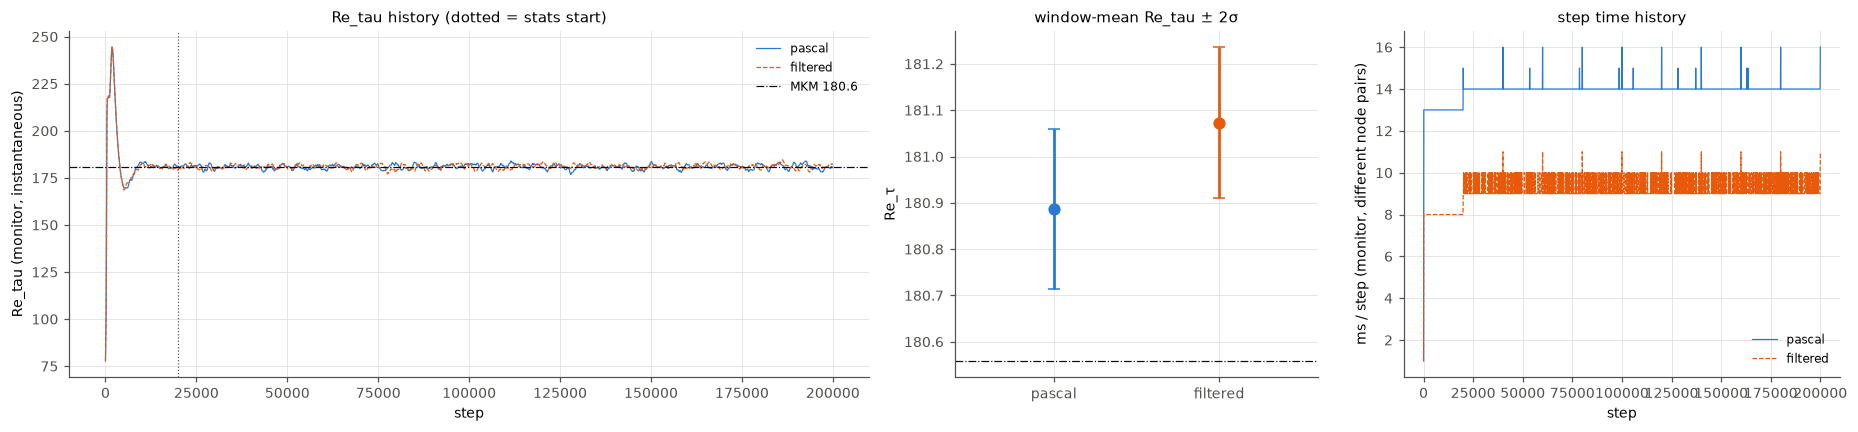

In [4]:
figure, axes = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw=dict(width_ratios=[2.2, 1, 1.2]))
for be, r in runs.items():
    m = r["monitor"]
    if m is None: continue
    axes[0].plot(m["step"], m["re_tau"], color=COLOR[be], ls=LS[be], lw=0.8, label=be)
    axes[2].plot(m["step"], m["sec"] * 1e3, color=COLOR[be], ls=LS[be], lw=0.8, label=be)
axes[0].axvline(20000, color=MUTED, lw=0.8, ls=":"); axes[0].axhline(RE_MKM, color=INK, lw=0.8, ls="-.", label=f"MKM {RE_MKM:.1f}")
axes[0].set_xlabel("step"); axes[0].set_ylabel("Re_tau (monitor, instantaneous)"); axes[0].set_title("Re_tau history (dotted = stats start)"); axes[0].legend()
if stat_ok:
    for i, be in enumerate(TAGS):
        r = runs[be]
        axes[1].errorbar(i, r["re_tau"][0], yerr=2 * r["re_tau"][1], fmt="o", color=COLOR[be], capsize=4, ms=7)
    axes[1].axhline(RE_MKM, color=INK, lw=0.8, ls="-.")
    axes[1].set_xticks(range(len(TAGS))); axes[1].set_xticklabels(list(TAGS)); axes[1].set_xlim(-0.6, len(TAGS) - 0.4)
    axes[1].set_title("window-mean Re_tau ± 2σ"); axes[1].set_ylabel("Re_τ")
axes[2].set_xlabel("step"); axes[2].set_ylabel("ms / step (monitor, different node pairs)"); axes[2].set_title("step time history"); axes[2].legend()
figure.tight_layout(); plt.show()

## 3. 프로파일 — MKM 180 대비

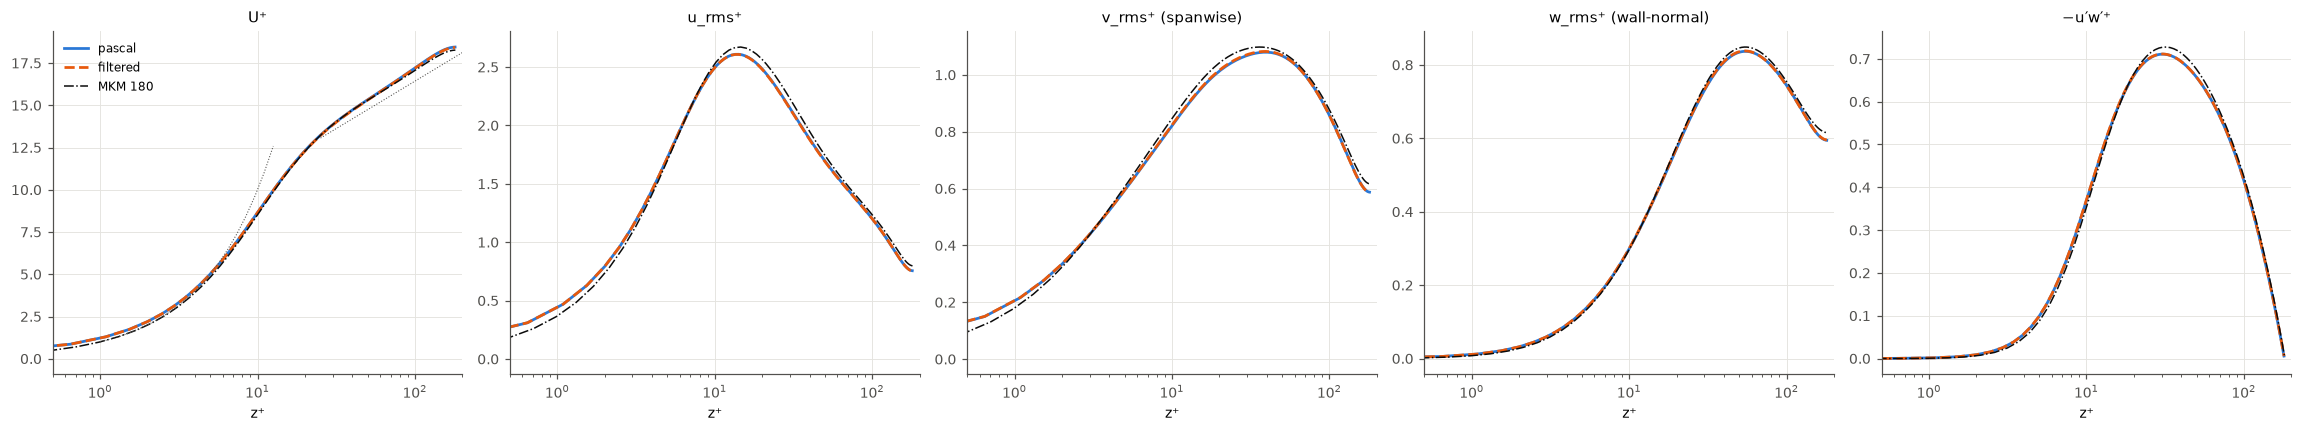

In [5]:
if stat_ok:
    figure, axes = plt.subplots(1, 5, figsize=(21, 4))
    for ax, (k, name) in zip(axes, PROFILE_KEYS):
        for be in TAGS:
            r = runs[be]; ax.plot(r["zp"], r[k][0], color=COLOR[be], ls=LS[be], label=be)
        ax.plot(mkm["zp"][1:], mkm[k][1:], color=INK, lw=1.0, ls="-.", label="MKM 180")
        ax.set_xscale("log"); ax.set_xlim(0.5, 200); ax.set_xlabel("z⁺"); ax.set_title(name)
    zz = np.logspace(0, 1.1, 20); axes[0].plot(zz, zz, color=MUTED, lw=0.7, ls=":")
    zz = np.logspace(1.4, 2.3, 20); axes[0].plot(zz, np.log(zz) / 0.41 + 5.2, color=MUTED, lw=0.7, ls=":")
    axes[0].legend(); figure.tight_layout(); plt.show()

## 4. 차이 Filtered − PaScaL 와 통계 오차 띠 (±2σ), z 값 프로파일

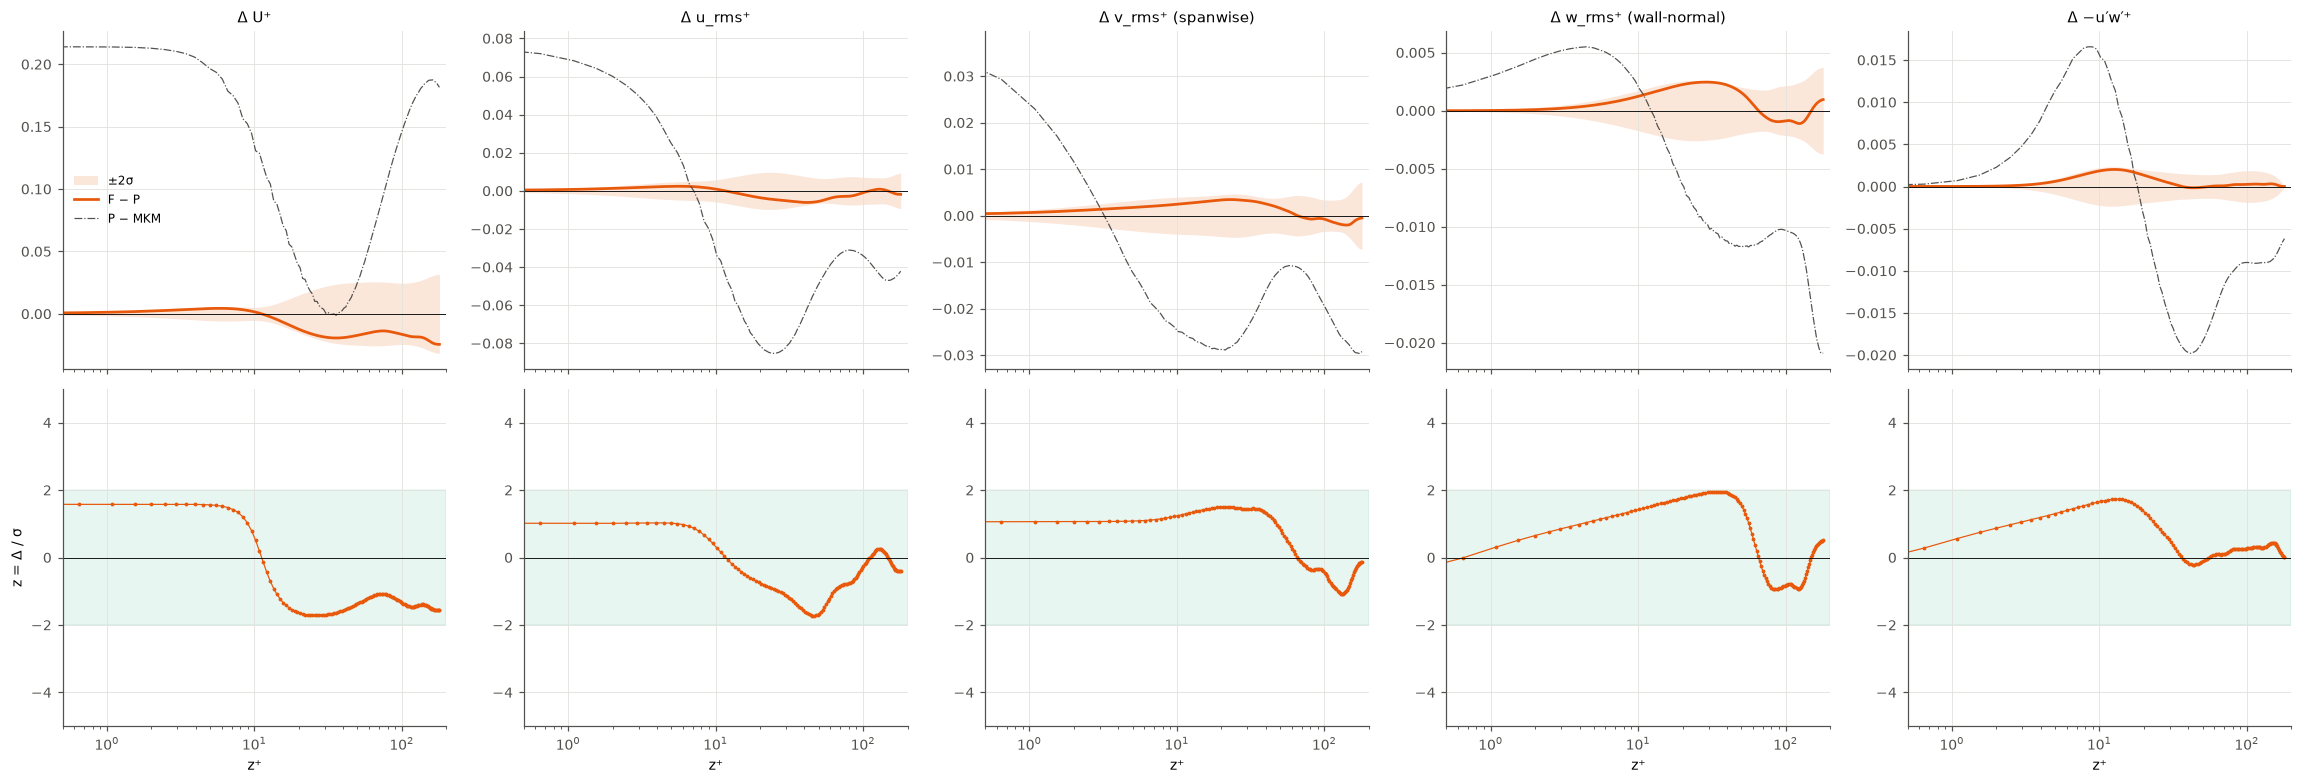

In [6]:
if stat_ok:
    P, F = runs["pascal"], runs["filtered"]
    figure, axes = plt.subplots(2, 5, figsize=(21, 7.2), sharex=True)
    for j, (k, name) in enumerate(PROFILE_KEYS):
        d = F[k][0] - P[k][0]; s = np.sqrt(F[k][1]**2 + P[k][1]**2)
        ax = axes[0, j]
        ax.fill_between(P["zp"], -2 * s, 2 * s, color=COLOR["filtered"], alpha=0.15, lw=0, label="±2σ")
        ax.plot(P["zp"], d, color=COLOR["filtered"], label="F − P")
        ax.plot(P["zp"], P[k][0] - mkm_at(k, P["zp"]), color=MUTED, lw=0.8, ls="-.", label="P − MKM")
        ax.axhline(0, color=INK, lw=0.6); ax.set_title(f"Δ {name}")
        ax = axes[1, j]
        ax.plot(P["zp"], zval(F, P, k), color=COLOR["filtered"], marker=".", ms=3, lw=0.8)
        ax.axhspan(-2, 2, color="#1baf7a", alpha=0.10); ax.axhline(0, color=INK, lw=0.6)
        ax.set_xscale("log"); ax.set_xlim(0.5, 200); ax.set_xlabel("z⁺"); ax.set_ylim(-5, 5)
    axes[0, 0].legend(); axes[1, 0].set_ylabel("z = Δ / σ")
    figure.tight_layout(); plt.show()

## 5. Filtered 절단 깊이 J

`truncation_J.dat`: 모니터 스텝마다 랭크(8) × 성분(dU·dV·dW) × 축(x·y·z) 의 J 와 fallback. 랭크당 128 행 → J ≤ 126.
J 가 작을수록 인터페이스 보정이 블록 안쪽으로 덜 전파된다(그만큼 일과 정확도를 줄인다). 허용오차 eps = dt·(L/N)² —
x 가 가장 성기다(Δx = 4π/256 ≈ 0.049, Δy ≈ 0.025, Δz̄ = 2/256 ≈ 0.0078).

J 기록: 모니터 스텝 2001 개 (1 … 200000), 행 16008 개; fallback 합 = 0
                           x                     y                     z
dU          2…  4 (평균  2.99)      2…  3 (평균  2.64)      7… 12 (평균  8.81)
dV          2…  3 (평균  2.96)      2…  3 (평균  2.65)      6… 11 (평균  8.45)
dW          2…  4 (평균  2.96)      2…  3 (평균  2.44)      8… 16 (평균 12.22)


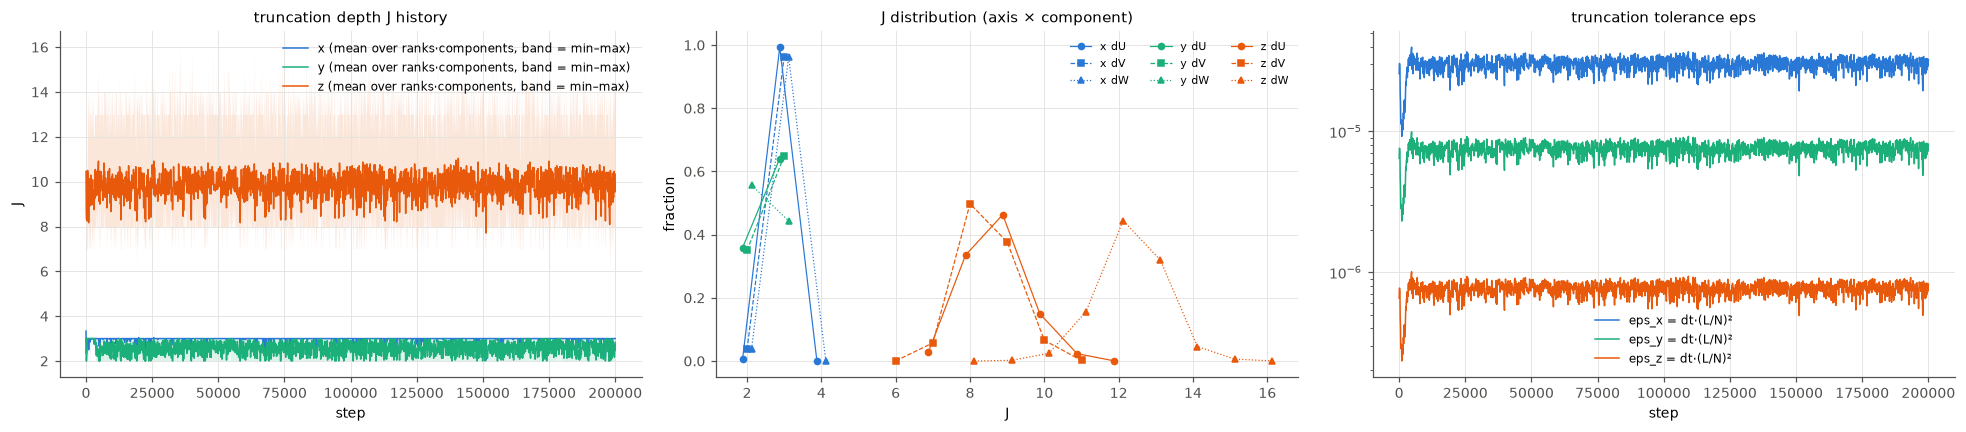

In [7]:
def read_truncation(tag):
    path = f"{APP}/stats_{tag}/truncation_J.dat"
    if not os.path.exists(path): return None
    d = np.loadtxt(path, comments="#")
    if d.ndim == 1: d = d[None, :]
    return dict(step=d[:, 0], dt=d[:, 1], rank=d[:, 2].astype(int), J=d[:, 3:12].reshape(-1, 3, 3).astype(int),  # [행, 성분, 축]
                fb=d[:, 12:21].reshape(-1, 3, 3).astype(int))
T = read_truncation(TAGS["filtered"])
COMP, AXES = ["dU", "dV", "dW"], ["x", "y", "z"]
if T is not None:
    steps = np.unique(T["step"])
    print(f"J 기록: 모니터 스텝 {len(steps)} 개 ({int(steps[0])} … {int(steps[-1])}), 행 {len(T['step'])} 개; fallback 합 = {T['fb'].sum()}")
    print(f"{'':<6}" + "".join(f"{a:>22}" for a in AXES))
    for c, cn in enumerate(COMP):
        cells = []
        for a in range(3):
            j = T["J"][:, c, a]
            cells.append(f"{j.min():3d}…{j.max():3d} (평균 {j.mean():5.2f})")
        print(f"{cn:<6}" + "".join(f"{x:>22}" for x in cells))
    figure, axes = plt.subplots(1, 3, figsize=(18, 4))
    for a, an in enumerate(AXES):
        jm = np.array([T["J"][T["step"] == s][:, :, a].mean() for s in steps])
        jlo = np.array([T["J"][T["step"] == s][:, :, a].min() for s in steps])
        jhi = np.array([T["J"][T["step"] == s][:, :, a].max() for s in steps])
        axes[0].fill_between(steps, jlo, jhi, color=AXIS_COLOR[an], alpha=0.15, lw=0)
        axes[0].plot(steps, jm, color=AXIS_COLOR[an], lw=1.0, label=f"{an} (mean over ranks·components, band = min–max)")
        for c, cn in enumerate(COMP):
            vals, counts = np.unique(T["J"][:, c, a], return_counts=True)
            axes[1].plot(vals + 0.12 * (c - 1), counts / counts.sum(), "o-" if c == 0 else ("s--" if c == 1 else "^:"),
                         color=AXIS_COLOR[an], ms=4, lw=0.8, label=f"{an} {cn}")
    axes[0].set_xlabel("step"); axes[0].set_ylabel("J"); axes[0].set_title("truncation depth J history"); axes[0].legend()
    axes[1].set_xlabel("J"); axes[1].set_ylabel("fraction"); axes[1].set_title("J distribution (axis × component)"); axes[1].legend(ncol=3, fontsize=7)
    dts = np.array([T["dt"][T["step"] == s][0] for s in steps])
    L = dict(x=4 * np.pi, y=2 * np.pi, z=2.0)
    for an in AXES: axes[2].semilogy(steps, dts * (L[an] / 256)**2, color=AXIS_COLOR[an], lw=1.0, label=f"eps_{an} = dt·(L/N)²")
    axes[2].set_xlabel("step"); axes[2].set_title("truncation tolerance eps"); axes[2].legend()
    figure.tight_layout(); plt.show()

## 6. 속도 — PaScaL vs Filtered (통계 런 자체에서)

**주 측정 = 통계 파일 쓰기 시각의 간격.** 루트가 1 만 스텝마다 `channel_stats_*.dat` 를 쓰므로 연속한 두 파일의 수정 시각 차 = 그 1 만 스텝의
벽시계(초 단위 → 0.1 ms/step 해상도, 시작 비용 제외). 2 만 스텝 배수 구간에는 537 MB 체크포인트 쓰기가 끼므로 **그 구간을 뺀 값**을 대표값으로 한다.
모니터의 sec/step 열은 `%8.3f`(1 ms 해상도)라 보조로만 본다. 두 런은 서로 다른 노드쌍에서 동시에 돌았다(노드 차이가 섞인다).
Filtered 런만 모니터 스텝마다 J 를 읽는 동기화가 9 번 더 있다(100 스텝당 — 무시할 수준).

          노드                   구간(ckpt 제외)            ms/step      구간(전체)   ms/step      모니터 평균
pascal    node[1359-1360]                8     13.825 ± 0.046          17    13.859       14.01
filtered  node[1706-1707]                8      9.500 ± 0.000          17     9.506        9.33

Filtered / PaScaL = 0.687 → Filtered 가 스텝당 4.33 ms (31.3 %) 빠름  (체크포인트 없는 1 만 스텝 구간 평균)
주의: 서로 다른 노드쌍 — 노드 간 차이가 섞인 값.


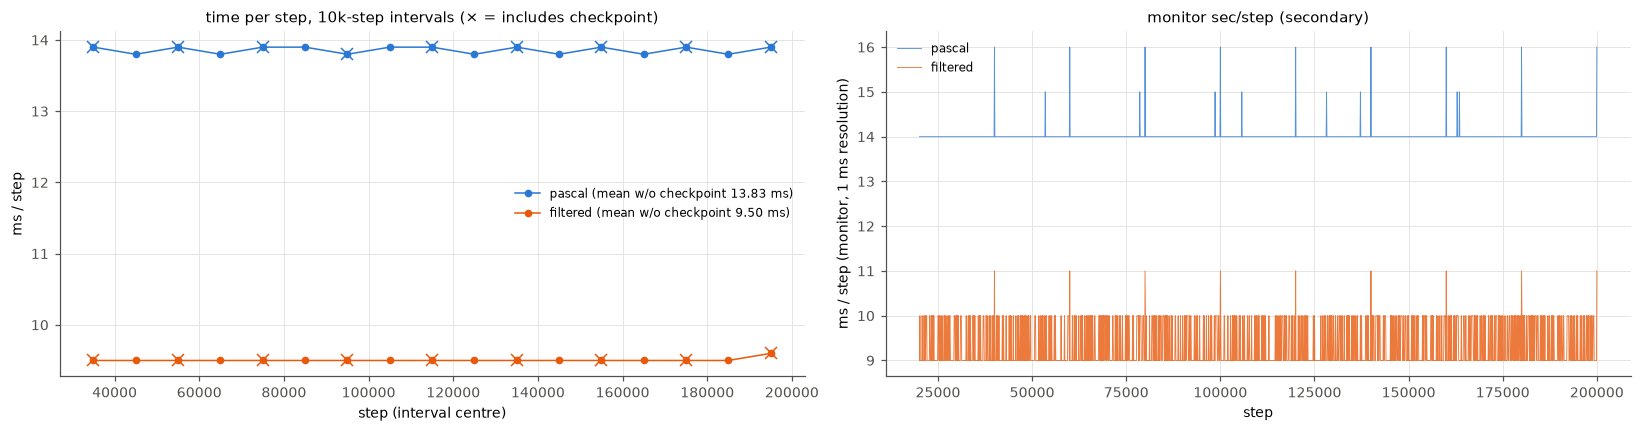

In [8]:
def job_nodes(backend):
    outs = sorted(glob.glob(f"{APP}/log/ftdma_{backend}_*.out"))
    if not outs: return "?"
    n = re.search(r"nodes=(\S+)", open(outs[-1]).read()); return n.group(1) if n else "?"

def interval_times(tag, checkpoint_every=20000):
    """통계 파일 수정 시각 → [(시작 스텝, 끝 스텝, 초, ms/step, 체크포인트 포함?)]."""
    files = sorted(glob.glob(f"{APP}/stats_{tag}/channel_stats_*.dat"))
    pts = [(int(re.search(r"(\d+)\.dat$", f).group(1)), os.path.getmtime(f)) for f in files]
    out = []
    for (s0, t0), (s1, t1) in zip(pts, pts[1:]):
        out.append((s0, s1, t1 - t0, 1e3 * (t1 - t0) / (s1 - s0), any(s % checkpoint_every == 0 for s in range(s0 + 1, s1 + 1))))
    return out

timing = {}
for be, tag in TAGS.items():
    iv = interval_times(tag)
    clean = np.array([x[3] for x in iv if not x[4]]); alls = np.array([x[3] for x in iv])
    m = runs[be]["monitor"]
    mon = m["sec"][m["step"] > 20000] * 1e3 if m is not None else np.array([])
    timing[be] = dict(iv=iv, clean=clean, all=alls, mon=mon, nodes=job_nodes(be))
print(f"{'':<9} {'노드':<15} {'구간(ckpt 제외)':>16} {'ms/step':>18} {'구간(전체)':>11} {'ms/step':>9} {'모니터 평균':>11}")
for be, r in timing.items():
    c = r["clean"]
    cs = f"{c.mean():7.3f} ± {c.std(ddof=1):5.3f}" if len(c) > 1 else (f"{c.mean():7.3f}" if len(c) else "—")
    print(f"{be:<9} {r['nodes']:<15} {len(c):16d} {cs:>18} {len(r['all']):11d} {r['all'].mean() if len(r['all']) else np.nan:9.3f} {r['mon'].mean() if len(r['mon']) else np.nan:11.2f}")
if all(len(timing[b]["clean"]) for b in TAGS):
    p, f = timing["pascal"]["clean"].mean(), timing["filtered"]["clean"].mean()
    print(f"\nFiltered / PaScaL = {f / p:.3f} → Filtered 가 스텝당 {p - f:.2f} ms ({100 * (1 - f / p):.1f} %) 빠름  (체크포인트 없는 1 만 스텝 구간 평균)")
    print("주의: 서로 다른 노드쌍 — 노드 간 차이가 섞인 값.")
    figure, axes = plt.subplots(1, 2, figsize=(15, 4))
    for be in TAGS:
        iv = timing[be]["iv"]
        mid = [0.5 * (a + b) for a, b, *_ in iv]; v = [x[3] for x in iv]; ck = [x[4] for x in iv]
        axes[0].plot(mid, v, "o-", color=COLOR[be], ms=4, lw=1.0, label=f"{be} (mean w/o checkpoint {timing[be]['clean'].mean():.2f} ms)")
        axes[0].plot([x for x, c in zip(mid, ck) if c], [y for y, c in zip(v, ck) if c], "x", color=COLOR[be], ms=8)
        m = runs[be]["monitor"]; sel = m["step"] > 20000
        axes[1].plot(m["step"][sel], m["sec"][sel] * 1e3, color=COLOR[be], lw=0.6, alpha=0.8, label=be)
    axes[0].set_xlabel("step (interval centre)"); axes[0].set_ylabel("ms / step"); axes[0].set_title("time per step, 10k-step intervals (× = includes checkpoint)"); axes[0].legend()
    axes[1].set_xlabel("step"); axes[1].set_ylabel("ms / step (monitor, 1 ms resolution)"); axes[1].set_title("monitor sec/step (secondary)"); axes[1].legend()
    figure.tight_layout(); plt.show()